# Model comparison, comparison charts and final model selection
**Assignment 1 - companion to `mnist_model_training.ipynb`**

The training notebook ran the hyper-parameter searches, trained the three final models and saved them to `../models`, together with the
results of the run in `../artifacts` (search tables, training histories, final metrics, training times).

This notebook is the **comparison stage**. It does not retrain anything:
1. loads the three **saved model files** from disk (so what is compared is exactly what the app uses),
2. re-evaluates them on the untouched 10,000-image MNIST test set,
3. combines this with the training-time / complexity / validation numbers stored by the training notebook,
4. draws the comparison charts, and
5. selects the best-suited model, justified by **performance, complexity, generalisation, training time and suitability for digit recognition**.

Run order: first `mnist_model_training.ipynb` (once), then this notebook.

## 1. Setup and loading the results of the training run

In [1]:
import sys
try:
    import torch, sklearn, seaborn, flask  # packages installed only in the project's .venv
except ModuleNotFoundError as e:
    raise RuntimeError(f"Wrong kernel: '{sys.executable}' is missing '{e.name}'. In VS Code click 'Select Kernel' (top right) -> "
                       "'Python Environments' -> choose the interpreter  <project>/.venv/Scripts/python.exe, then run again.") from None
print("kernel python:", sys.executable)
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch
from scipy.stats import binomtest
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score, confusion_matrix

from data_preprocessing import load_raw_mnist, scale_pixels, flatten, add_channel
from model_utils import predict_proba, count_parameters
import inference

ARTIFACTS, MODELS = Path("..") / "artifacts", Path("..") / "models"
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
NAMES = ["SVM", "MLP", "CNN"]
COLORS = {"SVM": "#c0504d", "MLP": "#4f81bd", "CNN": "#2e9e5b"}

stored = json.loads((ARTIFACTS / "final_results.json").read_text())
hist = json.loads((ARTIFACTS / "training_histories.json").read_text())
search = {n: pd.read_csv(ARTIFACTS / f"{n.lower()}_search.csv") for n in NAMES}
print("hyper-parameters selected by the training notebook:")
print(json.dumps(stored["hyperparameters"], indent=1))

kernel python: d:\secondry ssd\AAST\term7\prof\assighnments\mnist-digit-recognizer\.venv\Scripts\python.exe
hyper-parameters selected by the training notebook:
{
 "SVM": {
  "kernel": "rbf",
  "C": 5.0,
  "gamma": 0.02
 },
 "MLP": {
  "hidden": [
   512,
   256
  ],
  "lr": 0.001,
  "dropout": 0.3,
  "batch": 64,
  "wd": 0.0001
 },
 "CNN": {
  "filters": [
   32,
   64
  ],
  "lr": 0.003,
  "dropout": 0.0,
  "batch": 128,
  "wd": 0.0
 }
}


## 2. Re-evaluating the three saved models on the test set
The models are loaded with `inference.DigitRecognizer` - the same code path as the web app. The test set (10,000 images) was never used for any tuning decision.
Inference time is measured here on the whole test set (batch prediction, CPU).

In [2]:
rec = inference.DigitRecognizer()
_, _, x_test_raw, y_test = load_raw_mnist()
x_test = scale_pixels(x_test_raw)
flat, img = flatten(x_test), add_channel(x_test)

predictors = {"SVM": lambda: rec.models["svm"].predict(flat),
              "MLP": lambda: predict_proba(rec.models["mlp"], torch.from_numpy(flat)).argmax(1),
              "CNN": lambda: predict_proba(rec.models["cnn"], torch.from_numpy(img)).argmax(1)}
pred, infer_ms = {}, {}
for n in NAMES:
    t0 = time.perf_counter(); pred[n] = predictors[n](); infer_ms[n] = 1000 * (time.perf_counter() - t0) / len(y_test)
    print(f"{n}: test accuracy {accuracy_score(y_test, pred[n]):.4f} (training notebook reported {stored[n]['test_acc']:.4f}) | {infer_ms[n]:.3f} ms/image")
    assert abs(accuracy_score(y_test, pred[n]) - stored[n]["test_acc"]) < 1e-9, "saved model differs from the trained model!"
print("OK - the saved files reproduce exactly the test accuracy measured right after training.")

SVM: test accuracy 0.9851 (training notebook reported 0.9851) | 6.766 ms/image
MLP: test accuracy 0.9829 (training notebook reported 0.9829) | 0.049 ms/image
CNN: test accuracy 0.9901 (training notebook reported 0.9901) | 0.089 ms/image
OK - the saved files reproduce exactly the test accuracy measured right after training.


## 3. Comparison table
**Metrics**
* *Accuracy* - headline metric (ten balanced classes). *Macro precision / recall / F1* - average over the ten digits, each digit weighted equally.
* *Generalisation gap* = training accuracy - test accuracy (training accuracy was measured by the training notebook on a fixed 10,000-image subset of the training split). A small gap means the model does not just memorise.
* *Training time* - wall-clock seconds on this CPU, as measured by the training notebook (SVM: fit on 54k images; MLP/CNN: all epochs including a validation pass per epoch).
* *Complexity* - number of learnable parameters (MLP, CNN) or numbers stored in the support vectors (SVM), plus the size of the saved file.

In [3]:
rows = []
for n in NAMES:
    p, r, f, _ = precision_recall_fscore_support(y_test, pred[n], average="macro")
    s = stored[n]
    rows.append({"model": n, "train acc": s["train_acc"], "val acc": s["val_acc"], "TEST acc": accuracy_score(y_test, pred[n]),
                 "gen. gap": s["train_acc"] - accuracy_score(y_test, pred[n]), "macro P": p, "macro R": r, "macro F1": f,
                 "test errors": int((pred[n] != y_test).sum()), "train time (s)": s["train_time_s"], "inference (ms/img)": infer_ms[n],
                 "parameters": s["complexity"], "file size (MB)": s["file_mb"]})
comparison = pd.DataFrame(rows).set_index("model")
comparison.to_csv(ARTIFACTS / "model_comparison.csv")
fmt = {c: "{:.4f}" for c in ["train acc", "val acc", "TEST acc", "gen. gap", "macro P", "macro R", "macro F1"]}
fmt.update({"train time (s)": "{:.1f}", "inference (ms/img)": "{:.3f}", "parameters": "{:,.0f}", "file size (MB)": "{:.2f}", "test errors": "{:d}"})
display(comparison.style.format(fmt).highlight_max(subset=["TEST acc", "macro F1"], color="#cdeccd").highlight_min(subset=["gen. gap", "test errors", "train time (s)", "inference (ms/img)", "parameters", "file size (MB)"], color="#cdeccd"))

,train acc,val acc,TEST acc,gen. gap,macro P,macro R,macro F1,test errors,train time (s),inference (ms/img),parameters,file size (MB)
model,,,,,,,,,,,,
SVM,0.9999,0.9842,0.9851,0.0148,0.9851,0.9850,0.9850,149,172.4,6.766,"9,763,152",5.83
MLP,0.9968,0.9830,0.9829,0.0139,0.9830,0.9827,0.9828,171,52.3,0.049,"535,818",2.15
CNN,0.9969,0.9900,0.9901,0.0068,0.9900,0.9900,0.9900,99,18.7,0.089,"220,234",0.88


## 4. Comparison charts

### 4.1 Performance - accuracy and macro-F1 (axis zoomed to 96-100 %) and number of test errors

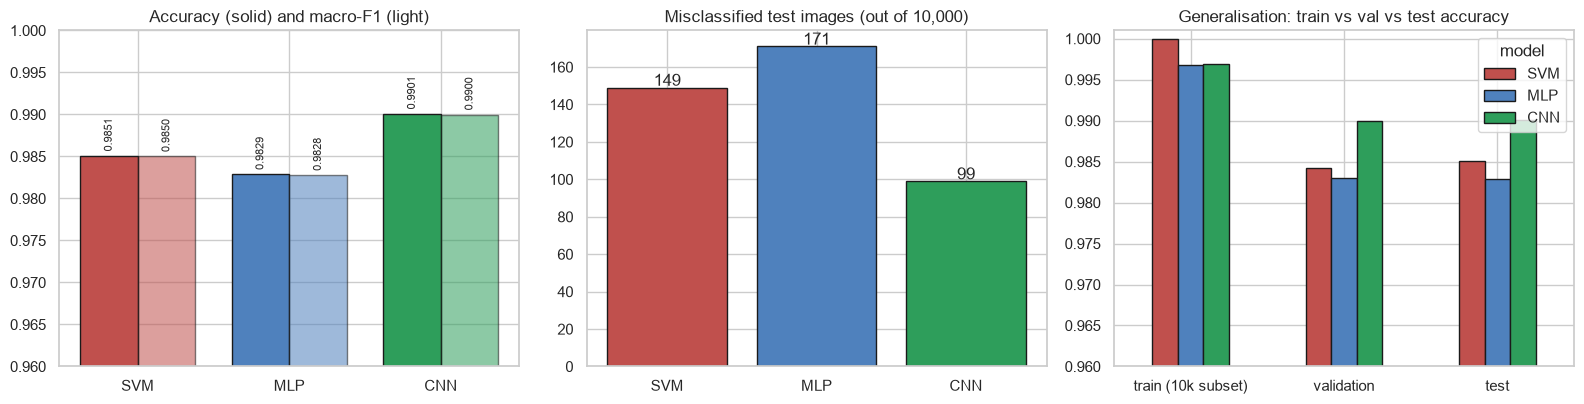

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
w = 0.38; xs = np.arange(3)
for i, (col, lab) in enumerate([("TEST acc", "test accuracy"), ("macro F1", "macro F1")]):
    vals = comparison[col].values
    b = ax[0].bar(xs + (i - 0.5) * w, vals, w, label=lab, color=[COLORS[n] for n in NAMES], alpha=1 if i == 0 else 0.55, edgecolor="k")
    for x, v in zip(xs + (i - 0.5) * w, vals): ax[0].text(x, v + 0.0005, f"{v:.4f}", ha="center", fontsize=8, rotation=90, va="bottom")
ax[0].set_xticks(xs); ax[0].set_xticklabels(NAMES); ax[0].set_ylim(0.96, 1.0); ax[0].set_title("Accuracy (solid) and macro-F1 (light)")
ax[1].bar(NAMES, comparison["test errors"], color=[COLORS[n] for n in NAMES], edgecolor="k")
for i, v in enumerate(comparison["test errors"]): ax[1].text(i, v + 1, str(v), ha="center")
ax[1].set_title("Misclassified test images (out of 10,000)")
tr = comparison[["train acc", "val acc", "TEST acc"]].T
tr.plot.bar(ax=ax[2], color=[COLORS[n] for n in NAMES], edgecolor="k"); ax[2].set_ylim(0.96, 1.001); ax[2].set_title("Generalisation: train vs val vs test accuracy")
ax[2].set_xticklabels(["train (10k subset)", "validation", "test"], rotation=0)
plt.tight_layout(); plt.savefig(ARTIFACTS / "cmp_performance.png", dpi=130); plt.show()

### 4.2 Cost - training time, inference time, complexity (log scales)

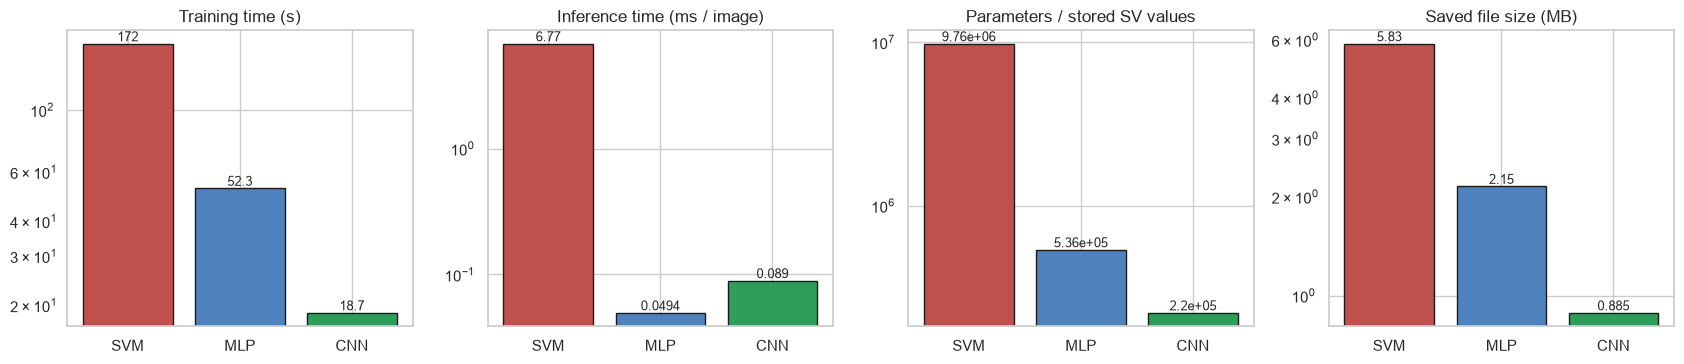

In [5]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, (col, title) in zip(ax, [("train time (s)", "Training time (s)"), ("inference (ms/img)", "Inference time (ms / image)"),
                                ("parameters", "Parameters / stored SV values"), ("file size (MB)", "Saved file size (MB)")]):
    a.bar(NAMES, comparison[col], color=[COLORS[n] for n in NAMES], edgecolor="k"); a.set_yscale("log"); a.set_title(title)
    for i, v in enumerate(comparison[col]): a.text(i, v, f"{v:,.3g}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.savefig(ARTIFACTS / "cmp_cost.png", dpi=130); plt.show()

### 4.3 Accuracy versus cost - the trade-off in one picture

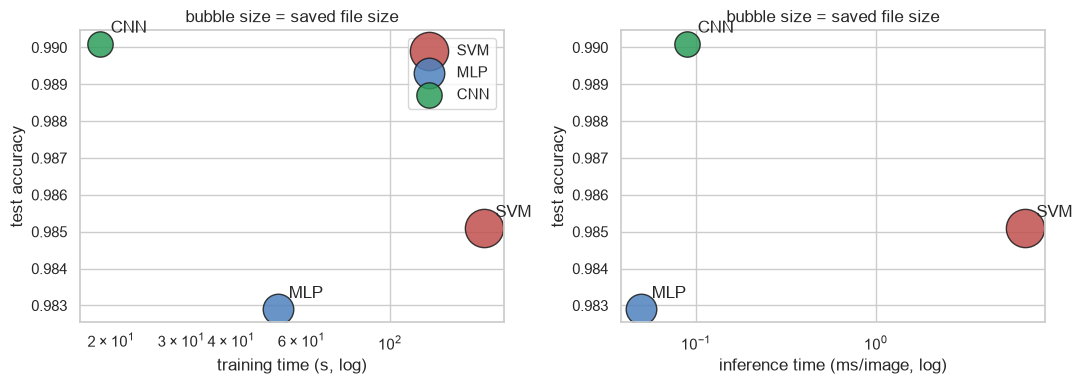

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (col, lab) in zip(ax, [("train time (s)", "training time (s, log)"), ("inference (ms/img)", "inference time (ms/image, log)")]):
    for n in NAMES:
        a.scatter(comparison.loc[n, col], comparison.loc[n, "TEST acc"], s=60 + 700 * np.sqrt(comparison.loc[n, "file size (MB)"] / comparison["file size (MB)"].max()),
                  color=COLORS[n], edgecolor="k", alpha=.85, label=n); a.annotate(n, (comparison.loc[n, col], comparison.loc[n, "TEST acc"]), xytext=(8, 8), textcoords="offset points")
    a.set_xscale("log"); a.set_xlabel(lab); a.set_ylabel("test accuracy"); a.set_title("bubble size = saved file size")
ax[0].legend(); plt.tight_layout(); plt.savefig(ARTIFACTS / "cmp_tradeoff.png", dpi=130); plt.show()

### 4.4 Learning curves of the two neural networks (from the training run)

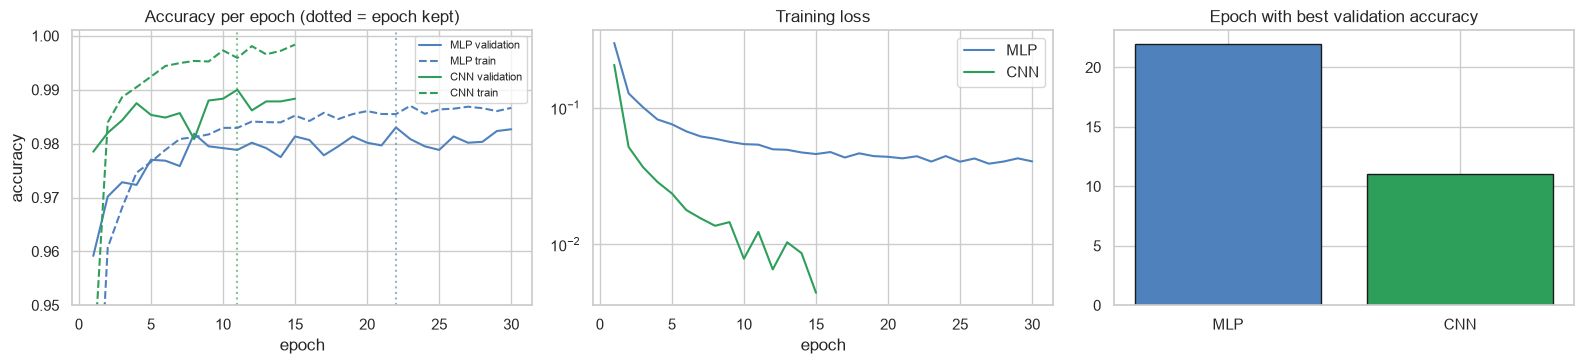

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for n, key in [("MLP", "MLP"), ("CNN", "CNN")]:
    h = hist[key]; e = range(1, len(h["val_acc"]) + 1)
    ax[0].plot(e, h["val_acc"], color=COLORS[n], label=f"{n} validation"); ax[0].plot(e, h["train_acc"], "--", color=COLORS[n], label=f"{n} train")
    ax[0].axvline(h["best_epoch"], color=COLORS[n], ls=":", alpha=.6)
    ax[1].plot(e, h["train_loss"], color=COLORS[n], label=n)
ax[0].set_ylim(0.95, 1.001); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("accuracy"); ax[0].legend(fontsize=8); ax[0].set_title("Accuracy per epoch (dotted = epoch kept)")
ax[1].set_yscale("log"); ax[1].set_xlabel("epoch"); ax[1].set_title("Training loss"); ax[1].legend()
ax[2].bar(["MLP", "CNN"], [hist[k]["best_epoch"] for k in ["MLP", "CNN"]], color=[COLORS["MLP"], COLORS["CNN"]], edgecolor="k"); ax[2].set_title("Epoch with best validation accuracy")
plt.tight_layout(); plt.savefig(ARTIFACTS / "cmp_learning_curves.png", dpi=130); plt.show()

### 4.5 Confusion matrices and per-class F1 (which digits are hard?)

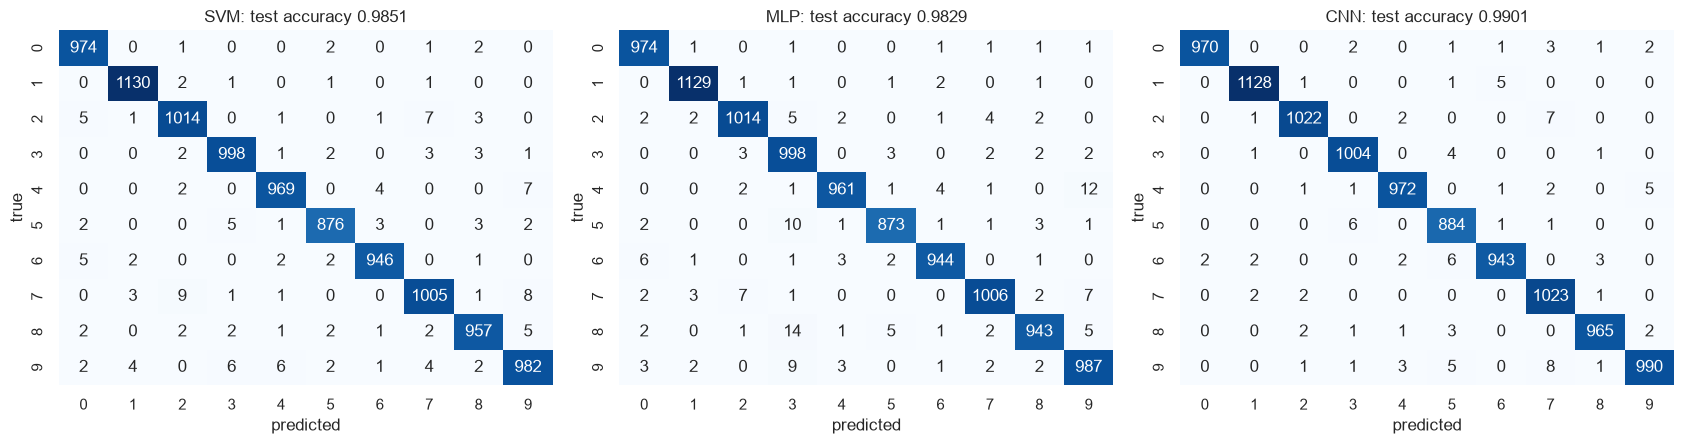

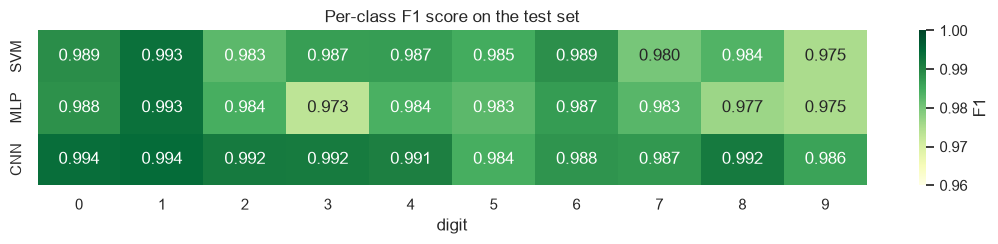

SVM most frequent mistakes (true->predicted: count): 7->2: 9, 7->9: 8, 2->7: 7
MLP most frequent mistakes (true->predicted: count): 8->3: 14, 4->9: 12, 5->3: 10
CNN most frequent mistakes (true->predicted: count): 9->7: 8, 2->7: 7, 6->5: 6


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, n in zip(axes, NAMES):
    sns.heatmap(confusion_matrix(y_test, pred[n]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{n}: test accuracy {accuracy_score(y_test, pred[n]):.4f}"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.savefig(ARTIFACTS / "cmp_confusion.png", dpi=130); plt.show()

per_class = pd.DataFrame({n: f1_score(y_test, pred[n], average=None) for n in NAMES}, index=range(10)).T
plt.figure(figsize=(11, 2.6)); sns.heatmap(per_class, annot=True, fmt=".3f", cmap="YlGn", vmin=.96, vmax=1.0, cbar_kws={"label": "F1"})
plt.xlabel("digit"); plt.title("Per-class F1 score on the test set"); plt.tight_layout(); plt.savefig(ARTIFACTS / "cmp_per_class_f1.png", dpi=130); plt.show()

for n in NAMES:
    cm = confusion_matrix(y_test, pred[n]); np.fill_diagonal(cm, 0)
    top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:3], cm.shape))[0]
    print(f"{n:3s} most frequent mistakes (true->predicted: count):", ", ".join(f"{a}->{b}: {cm[a, b]}" for a, b in top))

### 4.6 Hyper-parameter search overview (all configurations tried, validation accuracy)

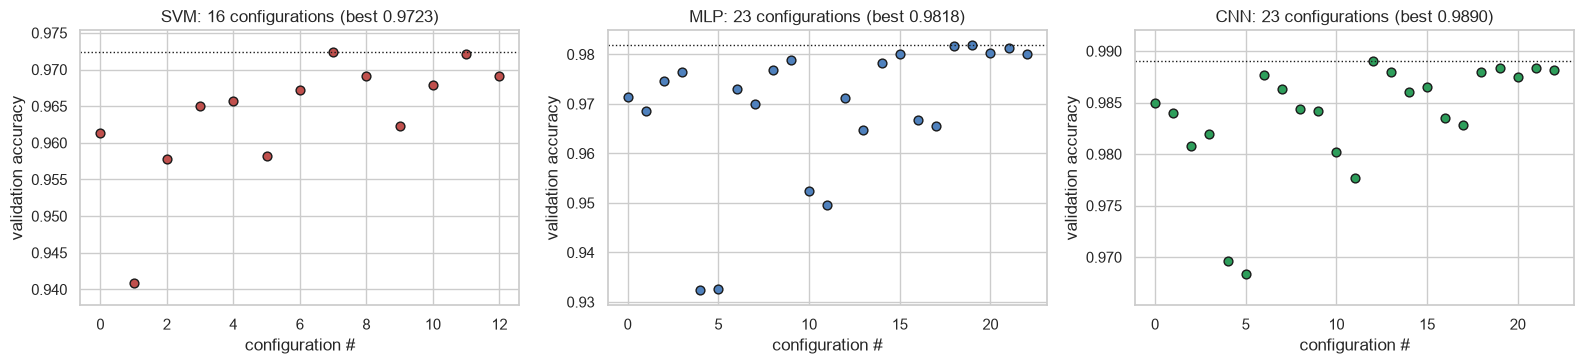

,configs tried,worst val acc,baseline/default val acc,best val acc
model,,,,
SVM,16,0.9132,0.9613,0.9723
MLP,23,0.9323,NaN,0.9818
CNN,23,0.9683,NaN,0.9890


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
rows = []
for a, n in zip(ax, NAMES):
    df = search[n]; df = df[df.stage != "1 kernel"] if n == "SVM" else df
    a.scatter(range(len(df)), df.val_acc.values, color=COLORS[n], edgecolor="k", s=40)
    a.axhline(df.val_acc.max(), color="k", ls=":", lw=1)
    lo = df.val_acc.min(); a.set_ylim(max(lo - 0.003, 0), df.val_acc.max() + 0.003)
    a.set_title(f"{n}: {len(search[n])} configurations (best {df.val_acc.max():.4f})"); a.set_xlabel("configuration #"); a.set_ylabel("validation accuracy")
    rows.append({"model": n, "configs tried": len(search[n]), "worst val acc": search[n].val_acc.min(), "baseline/default val acc": search[n].val_acc.iloc[0] if n == "SVM" else None, "best val acc": search[n].val_acc.max()})
plt.tight_layout(); plt.savefig(ARTIFACTS / "cmp_search_overview.png", dpi=130); plt.show()
display(pd.DataFrame(rows).set_index("model").round(4))

### 4.7 Are the differences between the models real?
With 10,000 test images one error is 0.01 %, so small gaps could be luck. We compare every pair on the **same images** with an exact McNemar test:
among the images where exactly one of the two models is right, is the split 50/50 (no real difference) or lopsided?

In [10]:
correct = {n: pred[n] == y_test for n in NAMES}
rows = []
for a, b in [("SVM", "MLP"), ("SVM", "CNN"), ("MLP", "CNN")]:
    only_a, only_b = int((correct[a] & ~correct[b]).sum()), int((~correct[a] & correct[b]).sum())
    p = binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    rows.append({"pair": f"{a} vs {b}", f"only first right": only_a, "only second right": only_b, "McNemar p-value": p, "significant (p<0.05)": p < 0.05})
display(pd.DataFrame(rows).set_index("pair"))
both_wrong = int((~correct["SVM"] & ~correct["MLP"] & ~correct["CNN"]).sum())
print(f"all three correct: {int((correct['SVM'] & correct['MLP'] & correct['CNN']).sum())} | all three wrong: {both_wrong} images (probably ambiguous/mislabelled digits)")

,only first right,only second right,McNemar p-value,significant (p<0.05)
pair,,,,
SVM vs MLP,69,47,5.072956e-02,False
SVM vs CNN,46,96,3.293876e-05,True
MLP vs CNN,50,122,3.952460e-08,True


all three correct: 9744 | all three wrong: 41 images (probably ambiguous/mislabelled digits)


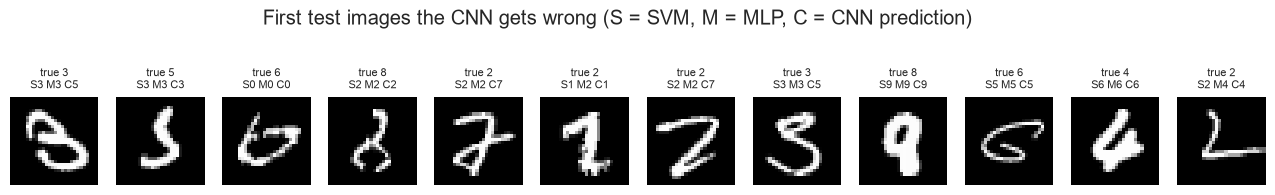

In [11]:
wrong = np.where(~correct["CNN"])[0][:12]
fig, axes = plt.subplots(1, len(wrong), figsize=(1.35 * len(wrong), 2.1))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.imshow(x_test[i], cmap="gray"); ax.axis("off"); ax.set_title(f"true {y_test[i]}\nS{pred['SVM'][i]} M{pred['MLP'][i]} C{pred['CNN'][i]}", fontsize=8)
plt.suptitle("First test images the CNN gets wrong (S = SVM, M = MLP, C = CNN prediction)", y=1.12); plt.show()

## 5. Ranking the models on the five required criteria

In [12]:
rank = pd.DataFrame(index=NAMES)
rank["Performance (test acc, macro-F1)"]   = comparison["TEST acc"].rank(ascending=False, method="min")
rank["Complexity (parameters, file size)"] = comparison["parameters"].rank(method="min")
rank["Generalisation (small train-test gap)"] = comparison["gen. gap"].rank(method="min")
rank["Training time"] = comparison["train time (s)"].rank(method="min")
rank["Inference speed"] = comparison["inference (ms/img)"].rank(method="min")
rank.astype(int).T.style.background_gradient(cmap="RdYlGn_r", vmin=1, vmax=3)

,SVM,MLP,CNN
"Performance (test acc, macro-F1)",2,3,1
"Complexity (parameters, file size)",3,2,1
Generalisation (small train-test gap),3,2,1
Training time,3,2,1
Inference speed,3,1,2


In [13]:
display(rank.astype(int).assign(total=rank.sum(axis=1).astype(int)).rename_axis("model"))
print("rank 1 = best on that criterion. 'Suitability for digit recognition' is a qualitative criterion - discussed in section 6.")

,"Performance (test acc, macro-F1)","Complexity (parameters, file size)",Generalisation (small train-test gap),Training time,Inference speed,total
model,,,,,,
SVM,2,3,3,3,3,14
MLP,3,2,2,2,1,10
CNN,1,1,1,1,2,6


rank 1 = best on that criterion. 'Suitability for digit recognition' is a qualitative criterion - discussed in section 6.
